# 1. モデル構成の比較（HAM10000）

ImageNet初期化・1-stage ERMで、ResNet-50・Spatial LoRA・HyperAdaptを3 seedずつ比べる。
CheXpertのM01・M03・M07と同じレシピで、データだけを替えたときに属性条件付きモデルとResNetの差が
test標本の雑音より大きくなるかを見る。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.ham10000_architecture_erm.comparison import (  # noqa: E402
    AXES,
    MODELS,
    evaluate_all,
    paired_bootstrap,
    plot_group_metric,
    plot_paired_deltas,
    plot_seed_points,
    prediction_command,
    read_scores,
    seed_deltas,
    select_runs,
)

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("ham10000_architecture_erm")
TOPIC = "01_architecture_comparison"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
N_BOOT = 1000

## 入力

モデル・seedごとに成功runを一意に選び、best `val/auroc` checkpointと学習時のtrain/val CSVをSHA256で照合する。
testは全runで同じCSVであることを確かめ、予測cacheの行順・targetを検算する。
cacheが欠けていれば、表示されるコマンドをrepo rootで実行する（推論GPUは自動で使わない）。

In [2]:
provenance, frame, directories = select_runs(PACKAGE)
provenance.to_csv(RESULTS / "provenance.csv", index=False)
print(prediction_command(PACKAGE, directories) or "全予測cacheが有効")
scores = read_scores(PACKAGE, directories, frame)

全予測cacheが有効


## 評価集合

主比較はsexとageが揃うtestの1,217件。残る294件（大半が別施設の`dataset=external`）は属性が欠損し、
条件付きモデルには学習中に一度も見ていない欠損入力が入るので、全1,511件は感度分析に回す。

In [3]:
complete = ~(frame["sex_missing"].astype(bool) | frame["age_missing"].astype(bool)).to_numpy()
PRIMARY = complete
print(f"主比較: {PRIMARY.sum():,}件（陽性 {frame.loc[PRIMARY, 'target'].sum()}）・{frame.loc[PRIMARY, 'lesion_id'].nunique()}病変")

主比較: 1,217件（陽性 190）・930病変


## 全体性能

閾値0.5（argmax）での指標。点がseed、横棒が3 seed平均。seed間のばらつきは学習の揺れで、test標本の雑音を含まない
（後段のpaired bootstrapで見る）。

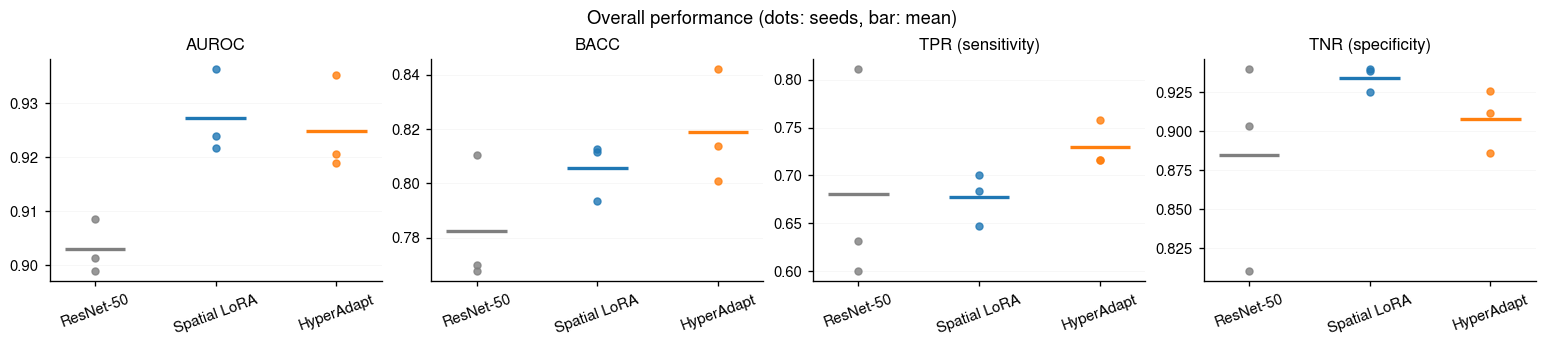

In [4]:
summary, groups = evaluate_all(scores, frame, PRIMARY)
summary.to_csv(RESULTS / "metrics_by_seed.csv", index=False)
groups.to_csv(RESULTS / "groups_by_seed.csv", index=False)
summary.groupby("model", sort=False).agg(["mean", "std"]).to_csv(RESULTS / "metrics_mean_std.csv")
overall = {"overall/auroc": "AUROC", "overall/bacc": "BACC", "overall/tpr": "TPR (sensitivity)", "overall/tnr": "TNR (specificity)"}
fig = plot_seed_points(summary, overall)
fig.suptitle("Overall performance (dots: seeds, bar: mean)", fontsize=11)
fig.savefig(FIGURES / "overall.png", dpi=150)

## 群別性能

群ごとのAUROC・TPR・TNR。陽性または陰性が20件未満のセルは指標を出さない（空欄）。
群名の下の陽性数/件数で、群の大きさを併せて読む。

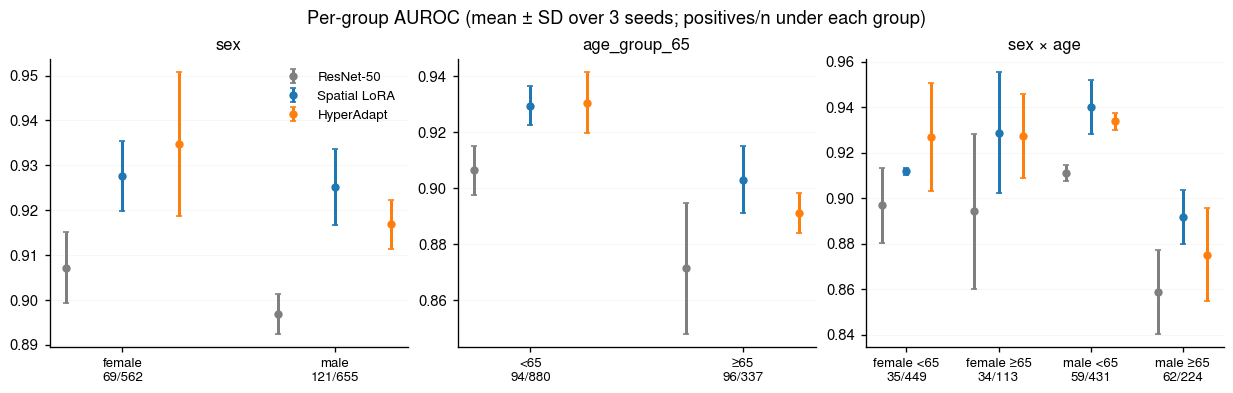

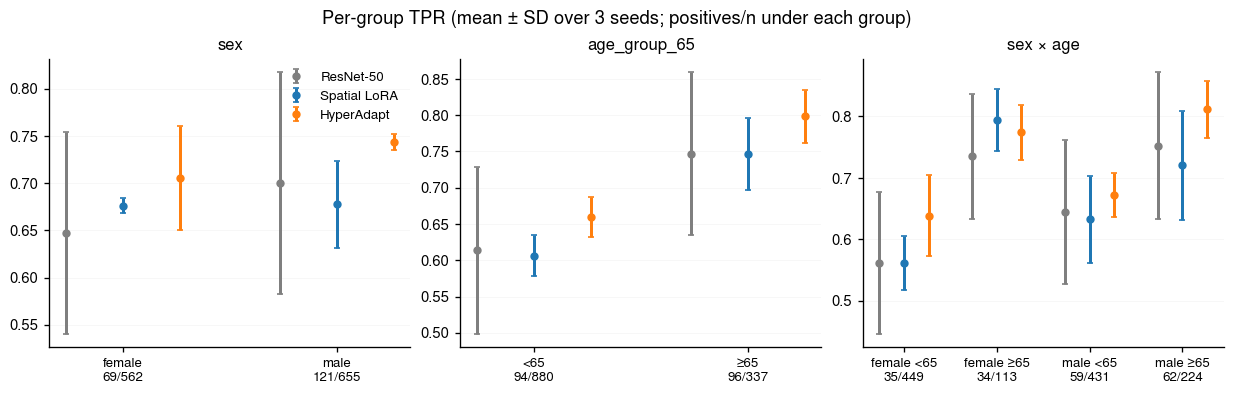

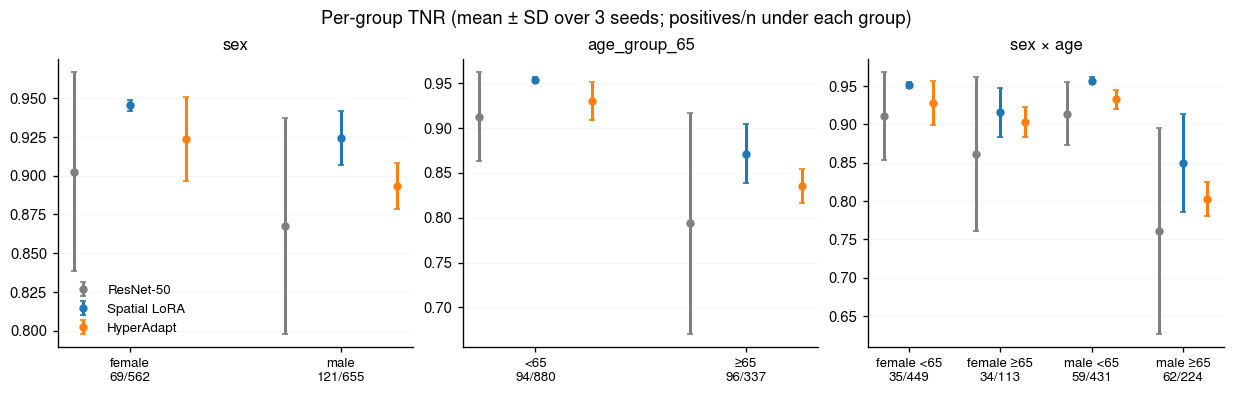

In [5]:
for metric in ("auroc", "tpr", "tnr"):
    fig = plot_group_metric(groups, metric)
    fig.savefig(FIGURES / f"groups_{metric}.png", dpi=150)

## 公平性指標

軸ごとのworst-group AUROC・AUROC gap・Eopp1（TPR gap）・Eopp0（TNR gap）・Eodds・BACC gap。
gap系は小さいほど公平。gapが縮んだときは、worstが上がったのかbestが下がったのかを前の群別図で確かめる。

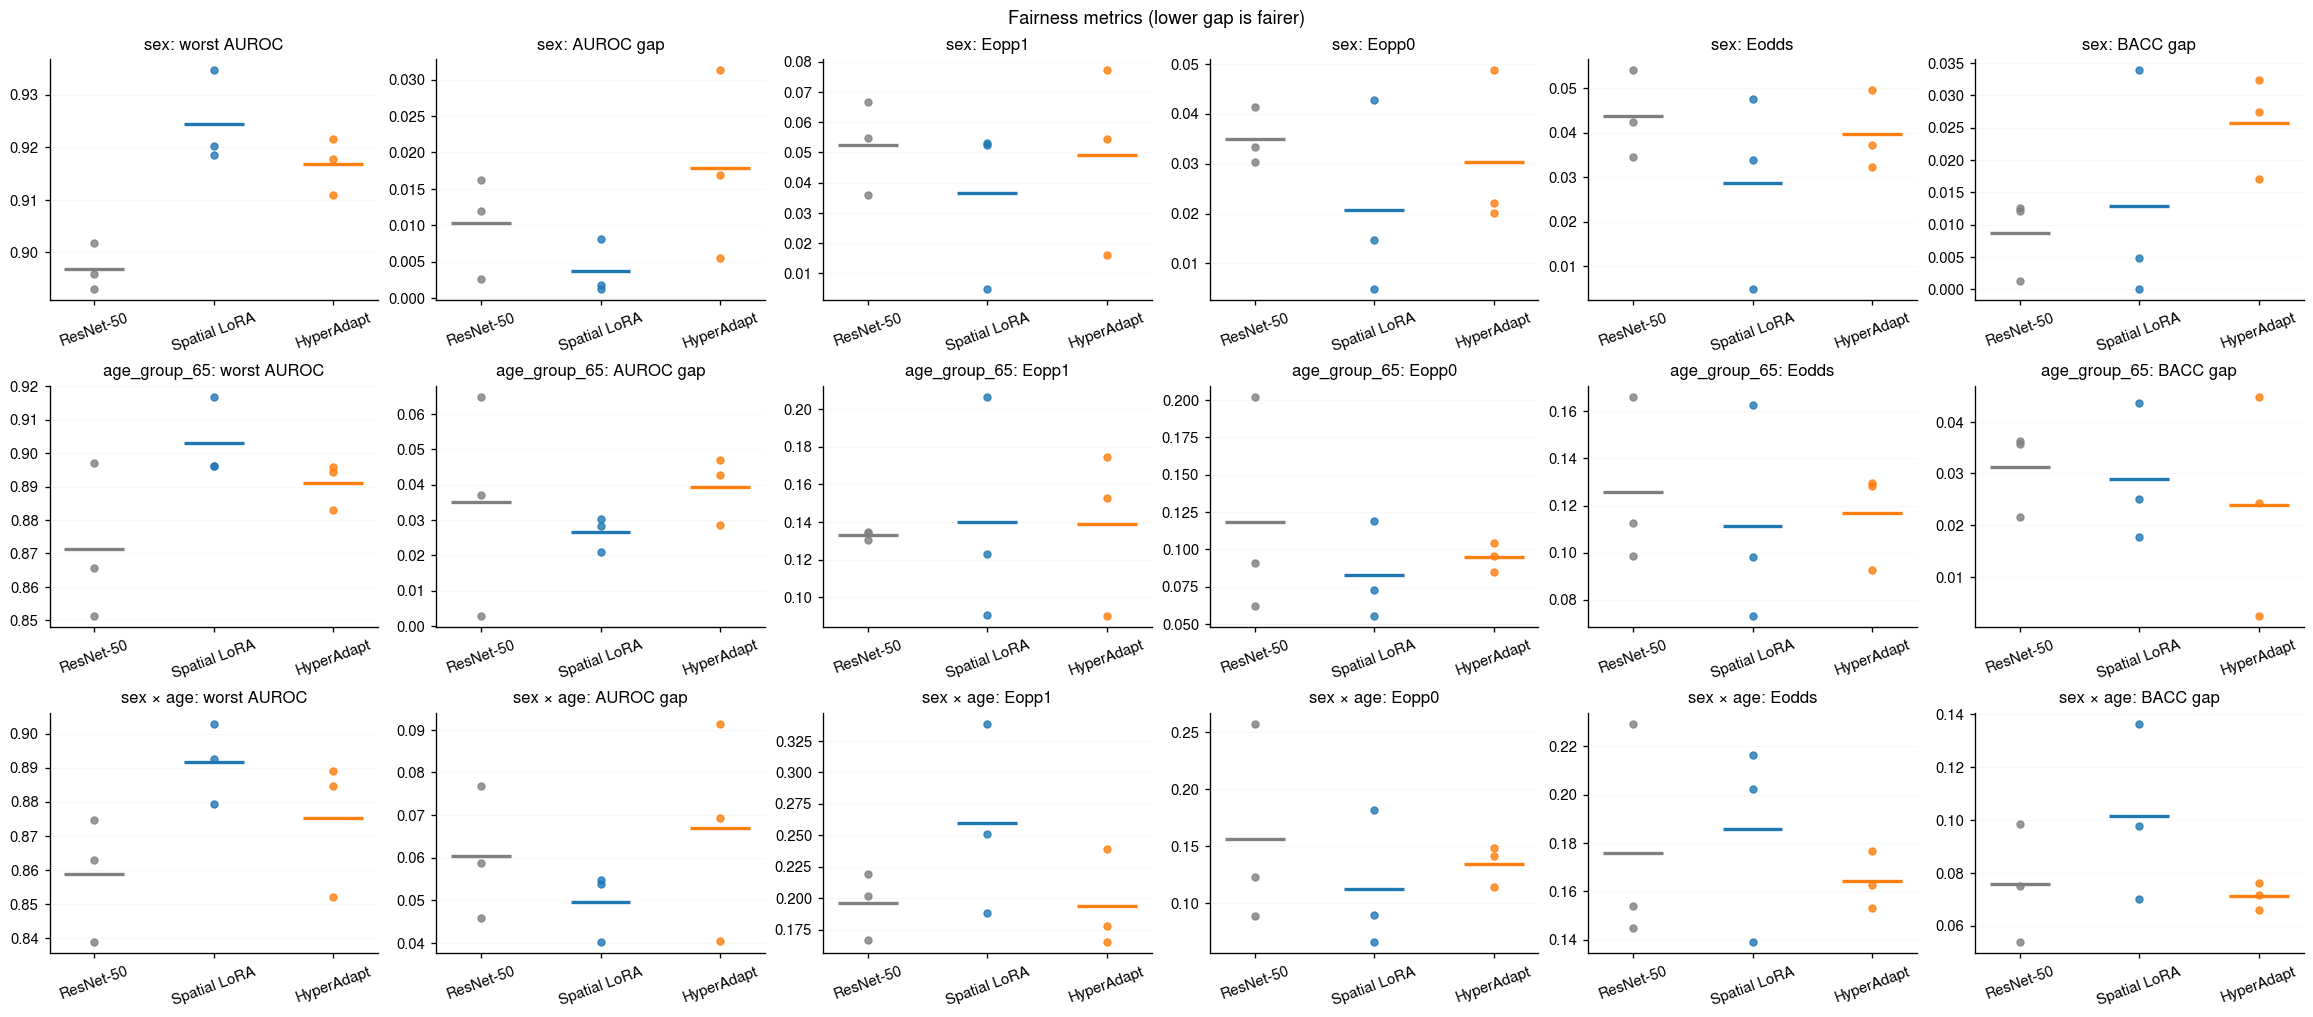

In [6]:
fairness = {}
for axis in AXES:
    for metric, name in [
        ("worst_auroc", "worst AUROC"),
        ("auroc_gap", "AUROC gap"),
        ("Eopp1", "Eopp1"),
        ("Eopp0", "Eopp0"),
        ("Eodds", "Eodds"),
        ("bacc_gap", "BACC gap"),
    ]:
        if summary[f"{axis}/{metric}"].notna().any():
            fairness[f"{axis}/{metric}"] = f"{axis}: {name}"
fig = plot_seed_points(summary, fairness, ncols=6)
fig.suptitle("Fairness metrics (lower gap is fairer)", fontsize=11)
fig.savefig(FIGURES / "fairness.png", dpi=150)

## ResNet-50との差とtest標本の雑音

比較モデル−ResNet-50を同seedで取り、3 seedで平均する。横棒は病変単位のpaired bootstrap（1000回）の95%区間で、
各反復で同じ再標本を全モデル・全seedに当てる。小点はseedごとの差。区間が0をまたぐ差は、
このtest集合では標本雑音と区別できない。

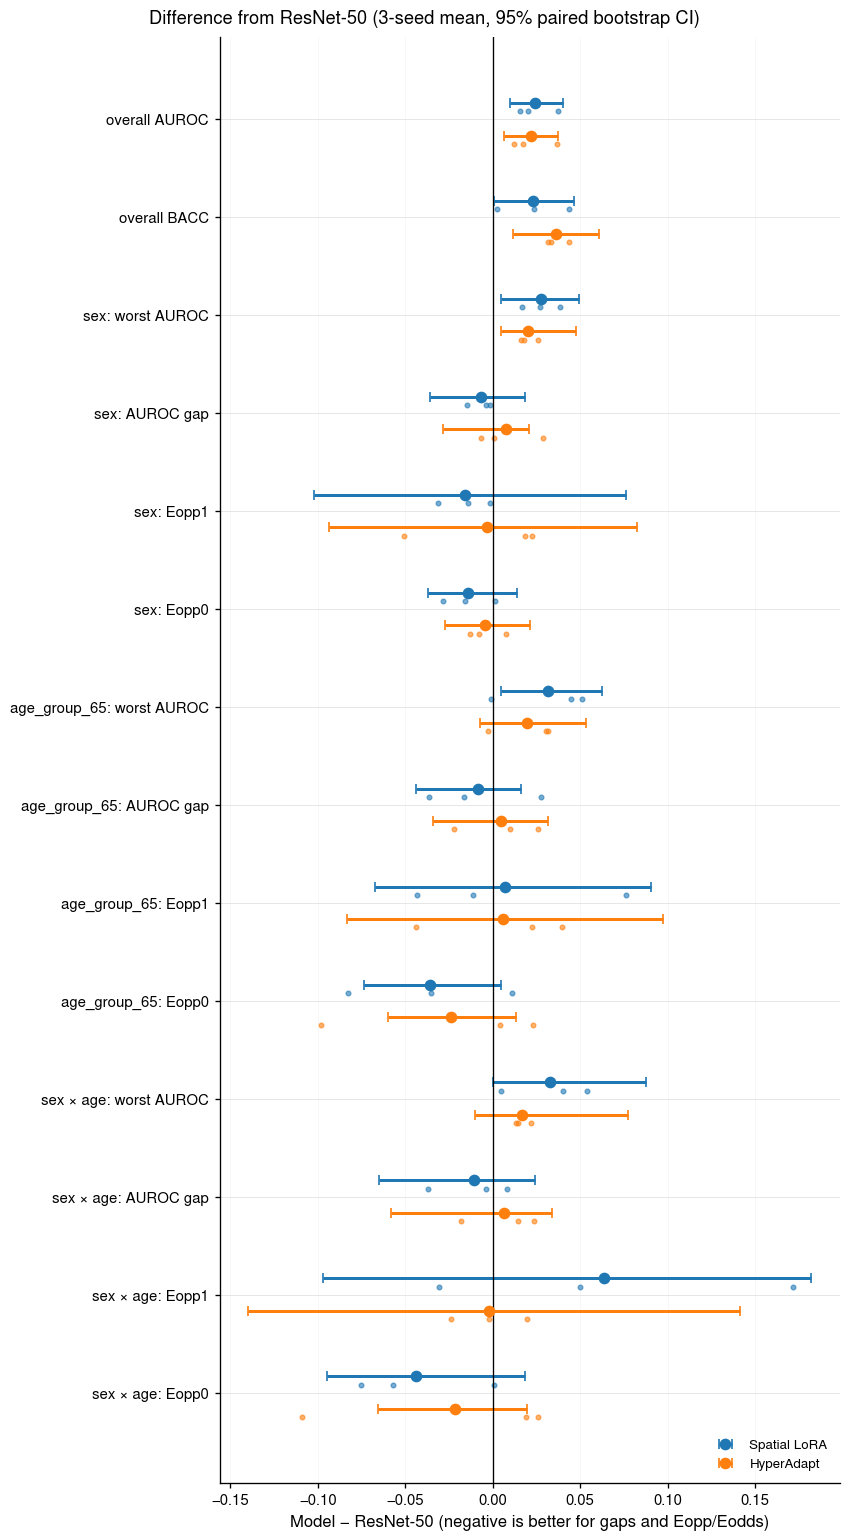

In [7]:
CLUSTERS = frame["lesion_id"].to_numpy()  # 同じ病変の複数画像をまとめて再標本化する

boot = paired_bootstrap(scores, frame, PRIMARY, CLUSTERS, n_boot=N_BOOT)
boot.to_csv(RESULTS / "paired_bootstrap.csv", index=False)
deltas = seed_deltas(summary)
deltas.to_csv(RESULTS / "paired_deltas_by_seed.csv", index=False)
headline = {"overall/auroc": "overall AUROC", "overall/bacc": "overall BACC"}
for axis in AXES:
    for metric, name in [("worst_auroc", "worst AUROC"), ("auroc_gap", "AUROC gap"), ("Eopp1", "Eopp1"), ("Eopp0", "Eopp0")]:
        if boot.loc[boot["metric"] == f"{axis}/{metric}", "valid_draws"].min() > 0.9 * N_BOOT:
            headline[f"{axis}/{metric}"] = f"{axis}: {name}"
fig = plot_paired_deltas(boot, deltas, headline)
fig.suptitle("Difference from ResNet-50 (3-seed mean, 95% paired bootstrap CI)", fontsize=11)
fig.savefig(FIGURES / "paired_deltas.png", dpi=150)

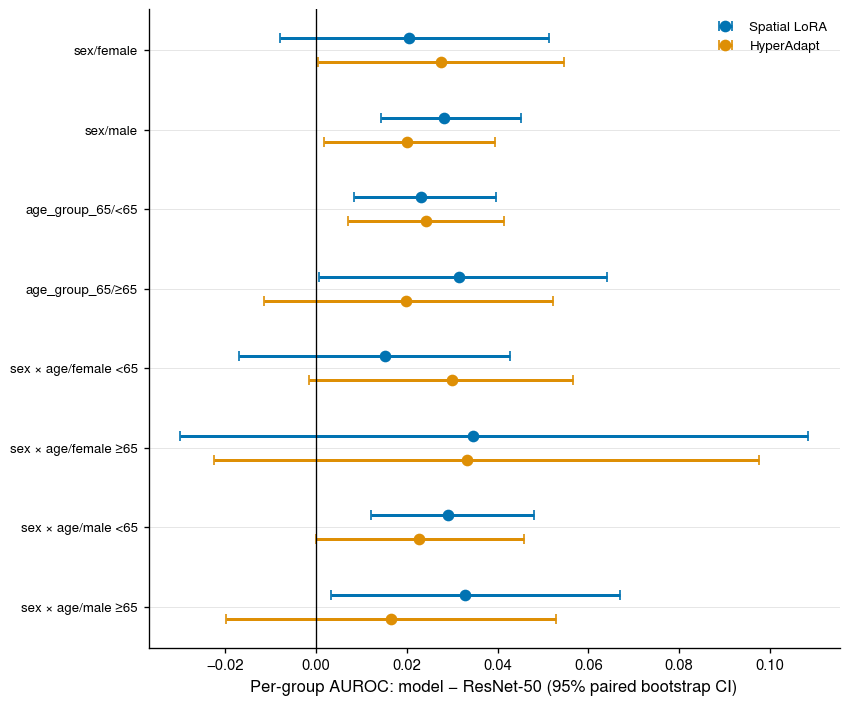

In [8]:
group_auroc = boot[boot["metric"].str.count("/") == 2]
group_auroc.to_csv(RESULTS / "paired_bootstrap_group_auroc.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 0.3 * len(group_auroc) + 1), layout="constrained")
for offset, (model, part) in enumerate(group_auroc.groupby("model", sort=False)):
    y = np.arange(len(part)) * 2 + offset * 0.6
    ax.errorbar(part["delta"], y, xerr=[part["delta"] - part["ci_low"], part["ci_high"] - part["delta"]],
                fmt="o", capsize=3, label=MODELS[model], color=f"C{offset}")
labels = group_auroc.loc[group_auroc["model"] == group_auroc["model"].iloc[0], "metric"].str.rsplit("/", n=1).str[0]
ax.set_yticks(np.arange(len(labels)) * 2 + 0.3, labels, fontsize=8)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Per-group AUROC: model − ResNet-50 (95% paired bootstrap CI)")
ax.legend(fontsize=8)
fig.savefig(FIGURES / "paired_deltas_group_auroc.png", dpi=150)

## 感度分析

評価集合を替えても同じ傾向かを見る。

- 全1,511件：属性欠損の294件を含む。全体指標だけを見る（群は属性の揃う行だけで決まる）
- 病理確定（`dx_type=histo`）のみ：属性の揃う行のうち649件で、陽性190件をすべて含む。
  経過観察（`follow_up`）など診断根拠と施設で簡単に分かれる良性例を除いた、難しい側の集合

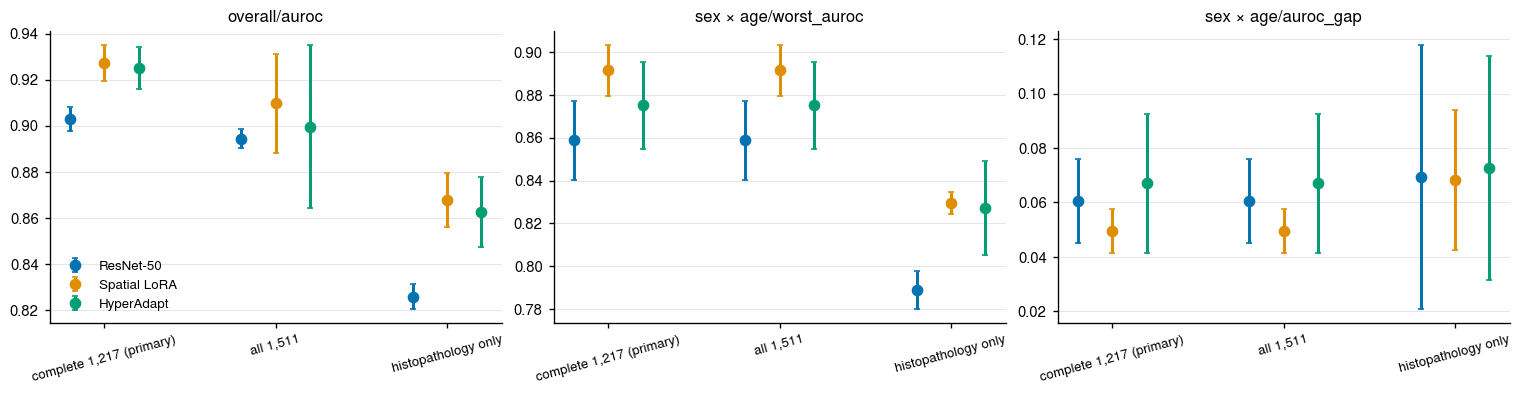

In [9]:
histo = complete & (frame["dx_type"] == 3).to_numpy()
sets = {"complete 1,217 (primary)": complete, "all 1,511": np.ones(len(frame), bool), "histopathology only": histo}
rows = []
for name, mask in sets.items():
    part, _ = evaluate_all(scores, frame, mask)
    rows.append(part.assign(evaluation_set=name, n=int(mask.sum()), n_positive=int(frame.loc[mask, "target"].sum())))
sensitivity = pd.concat(rows, ignore_index=True)
sensitivity.to_csv(RESULTS / "sensitivity_by_seed.csv", index=False)
metrics = ["overall/auroc", "sex × age/worst_auroc", "sex × age/auroc_gap"]
fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.2), layout="constrained")
for ax, metric in zip(axes, metrics, strict=True):
    for offset, model in enumerate(MODELS):
        stats = sensitivity[sensitivity["model"] == model].groupby("evaluation_set", sort=False)[metric].agg(["mean", "std"])
        ax.errorbar(np.arange(len(stats)) + (offset - 1) * 0.2, stats["mean"], yerr=stats["std"], fmt="o", capsize=2,
                    label=MODELS[model], color=f"C{offset}")
    ax.set_xticks(range(len(sets)), sets.keys(), rotation=15, fontsize=8)
    ax.set_title(metric, fontsize=10)
axes[0].legend(fontsize=8)
fig.savefig(FIGURES / "sensitivity.png", dpi=150)

## まとめ

**観察事実**（主比較：属性の揃う1,217件、3 seed、差は同seed差の平均と病変単位bootstrapの95%区間）

- 全体AUROCはResNet-50 0.903（SD 0.005）に対し、Spatial LoRA 0.927・HyperAdapt 0.925。
  差は+0.024［0.010, 0.040］・+0.022［0.006, 0.037］で、3 seedとも正。BACCも両モデルで上がる。
- 群別AUROCは4つの交差群すべてで同じ向きに+0.015〜0.035上がる。worst-group AUROCはsex軸・age軸で上がる。
- AUROC gap・Eopp0・Eopp1・Eoddsの差は、どの軸でも区間が0をまたぐ。群間の差は縮みも広がりもしていない。
- 病理確定の症例だけで見ると差は広がる（ResNet-50 0.826 → 0.868・0.862）。全1,511件でも向きは同じ。

**解釈候補**

- 属性条件付きモデルは、属性（特に部位）を予測の追加情報として使い、全群を一様に底上げしている。
  公平性（群間の差）の改善ではなく、全体性能の改善として現れている。
- CheXpertで差が見えなかったのとは対照的に、HAM10000ではモデル構成の差がtest標本の雑音より大きい。
  ただし属性入力の効果と、adapterによる容量の増加は分けていない。

**追加確認**

- 属性を入れ替えた・固定した反実仮想入力で、ResNet-50との差が消えるか
- 画像特徴と属性を最後に結合するだけのResNet-50（late fusion）で、同じ差が出るか